In [1]:
from pathlib import Path
import polars as pl
from models import data_loader as dl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


DEFAULT_CSV = Path("data/processed/monthly_statistical_bfis/nrb_balance_sheet.csv")

df = pl.read_csv(DEFAULT_CSV)

print(f"shape of full dataset {df.shape}")

# Build a native regex pattern matching any of the commercial bank prefixes at the start
commercial_pattern = "^(" + "|".join(dl.COMMERCIAL_BANK_PREFIXES) + ")"

df = df.filter(
    ~pl.col("bfi_name").str.ends_with("DB")
    & pl.col("bfi_name").str.contains(commercial_pattern)
)

print(
    f"shape of only comm bank dataset {df.shape} Rows: {df.height:,},"
    f" Columns: {df.width}"
)

print("\n=== SUMMARY STATISTICS (value_mn_npr) ===")
val_series = df["value_mn_npr"]

# Compute standard moments and metrics using Polars expressions
stats = df.select(
    [
        pl.col("value_mn_npr").count().alias("count"),
        pl.col("value_mn_npr").mean().alias("mean"),
        pl.col("value_mn_npr").median().alias("median"),
        pl.col("value_mn_npr").std().alias("std_dev"),
        pl.col("value_mn_npr").skew().alias("skewness"),
        pl.col("value_mn_npr").min().alias("min"),
        pl.col("value_mn_npr").max().alias("max"),
    ]
)
print(stats)

print("\n=== RECORD COUNTS BY BFI ===")
bfi_counts = df.group_by("bfi_name").len().sort("len", descending=True)
print(bfi_counts)

print("\n=== RECORD COUNTS BY FISCAL YEAR (BS) ===")
year_counts = df.group_by("year_bs").len().sort("year_bs")
print(year_counts)

print("\n=== CHECKING NULL / NAN COUNTS ===")
null_nan_summary = df.select(
    [
        pl.col("value_mn_npr").is_null().sum().alias("null_count"),
        # is_nan() only works on float columns; checks for IEEE 754 NaN values
        pl.col("value_mn_npr").is_nan().sum().alias("nan_count"),
    ]
)
print(null_nan_summary)

# Isolate missing/null value records
nnal = df.filter(
    pl.col("value_mn_npr").is_null() | pl.col("value_mn_npr").is_nan()
)

print(f"\nTotal rows with missing values: {nnal.height:,}")

if nnal.height > 0:
    print("\n=== MISSING VALUES GROUPED BY LINE ITEM ===")
    missing_breakdown = (
        nnal.group_by("line_item")
        .len(name="count_nnal")
        .sort("count_nnal", descending=True)
        .to_dicts()
    )
for item in missing_breakdown:
    print(item)
else:
    print("\n[INFO] No null or NaN values found in 'value_mn_npr'!")

shape of full dataset (330878, 9)
shape of only comm bank dataset (301429, 9) Rows: 301,429, Columns: 9

=== SUMMARY STATISTICS (value_mn_npr) ===
shape: (1, 7)
┌────────┬──────────────┬─────────┬──────────────┬──────────┬───────────┬───────────┐
│ count  ┆ mean         ┆ median  ┆ std_dev      ┆ skewness ┆ min       ┆ max       │
│ ---    ┆ ---          ┆ ---     ┆ ---          ┆ ---      ┆ ---       ┆ ---       │
│ u64    ┆ f64          ┆ f64     ┆ f64          ┆ f64      ┆ f64       ┆ f64       │
╞════════╪══════════════╪═════════╪══════════════╪══════════╪═══════════╪═══════════╡
│ 301068 ┆ 12082.202056 ┆ 509.525 ┆ 43677.455434 ┆ 7.025637 ┆ -18839.29 ┆ 852869.26 │
└────────┴──────────────┴─────────┴──────────────┴──────────┴───────────┴───────────┘

=== RECORD COUNTS BY BFI ===
shape: (33, 2)
┌──────────┬───────┐
│ bfi_name ┆ len   │
│ ---      ┆ ---   │
│ str      ┆ u64   │
╞══════════╪═══════╡
│ RBB      ┆ 12882 │
│ NABIL    ┆ 12837 │
│ EBL      ┆ 12777 │
│ HBL      ┆ 12770 │
│ N

In [2]:
print("\n=== REQUIRED-FIELD PRESENCE CHECK (via data_loader's own matching logic) ===")
# Reuses dl._lookup_field/_normalize_label directly.
non_blank = df.filter(pl.col("value_mn_npr").is_not_null())

cell_records: dict[tuple[str, int, str], dict[str, float]] = {}
for bfi_name, year_bs, month_bs, line_item, value in non_blank.select(
    ["bfi_name", "year_bs", "month_bs", "line_item", "value_mn_npr"]
).iter_rows():
    key = (bfi_name, year_bs, month_bs)
    cell_records.setdefault(key, {})[dl._normalize_label(line_item)] = value

n_cells = len(cell_records)
print(f"total (bfi, period) cells: {n_cells:,}")

required_fields = {
    k: v[1]
    for k, v in dl.FIELD_LABELS.items()
    if k in ("capital_fund", "liquid_funds", "loans_advances", "deposits")
}

for field, line_item in required_fields.items():
    missing_cells = []
    for key, rec in cell_records.items():
        try:
            dl._lookup_field(rec, line_item)
        except KeyError:
            missing_cells.append(key)
    print(f"{field:>15} ('{line_item}'): missing in {len(missing_cells):,} / {n_cells:,} cells")
    if missing_cells:
        missing_df = pl.DataFrame(
            missing_cells, schema=["bfi_name", "year_bs", "month_bs"], orient="row"
        )
        print(missing_df.group_by("bfi_name").len().sort("len", descending=True).head(10))

print("\n=== BORROWINGS SUBTOTAL FALLBACK RATE (via data_loader's own matching logic) ===")
fallback_cells = []
for key, rec in cell_records.items():
    try:
        dl._lookup_field(rec, dl.FIELD_LABELS["borrowings_total"][1])
    except KeyError:
        fallback_cells.append(key)
print(
    f"'2 BORROWINGS' subtotal row absent in {len(fallback_cells):,} / {n_cells:,} cells "
    f"(these fall back to summing BORROWING_SUBITEMS instead)"
)



=== REQUIRED-FIELD PRESENCE CHECK (via data_loader's own matching logic) ===
total (bfi, period) cells: 3,746
   capital_fund ('1 CAPITAL FUND'): missing in 0 / 3,746 cells
   liquid_funds ('1 LIQUID FUNDS'): missing in 0 / 3,746 cells
 loans_advances ('4 LOANS & ADVANCES'): missing in 0 / 3,746 cells
       deposits ('3 DEPOSITS'): missing in 0 / 3,746 cells

=== BORROWINGS SUBTOTAL FALLBACK RATE (via data_loader's own matching logic) ===
'2 BORROWINGS' subtotal row absent in 312 / 3,746 cells (these fall back to summing BORROWING_SUBITEMS instead)



=== GENERATING TIME-SERIES AGGREGATION & PLOT ===


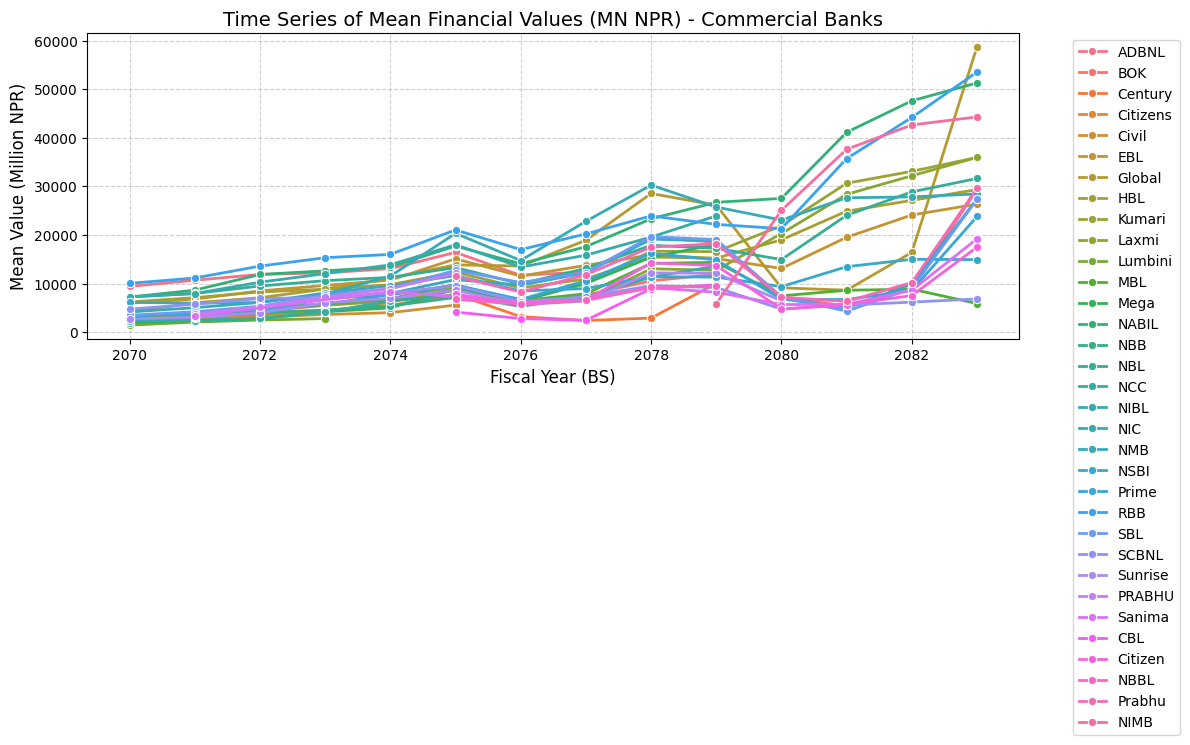

[INFO] Time series plot successfully saved to 'commercial_banks_timeseries.png'.


In [3]:
print("\n=== GENERATING TIME-SERIES AGGREGATION & PLOT ===")
# Aggregate mean value by year and commercial bank
ts_agg = (
    df.group_by(["year_bs", "bfi_name"])
    .agg(pl.col("value_mn_npr").mean().alias("mean_value"))
    .sort(["year_bs", "bfi_name"])
)

# Convert to pandas for plotting with Seaborn / Matplotlib
pdf = ts_agg.to_pandas()

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=pdf,
    x="year_bs",
    y="mean_value",
    hue="bfi_name",
    marker="o",
    linewidth=2,
)
plt.title(
    "Time Series of Mean Financial Values (MN NPR) - Commercial Banks",
    fontsize=14,
)
plt.xlabel("Fiscal Year (BS)", fontsize=12)
plt.ylabel("Mean Value (Million NPR)", fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

output_plot = Path("commercial_banks_timeseries.png")
# plt.savefig(output_plot, dpi=300)
plt.show()
print(f"[INFO] Time series plot successfully saved to '{output_plot}'.")

In [4]:
from pathlib import Path
import polars as pl
from models import data_loader as dl
import matplotlib.pyplot as plt
import seaborn as sns


DEFAULT_CSV = Path("data/processed/monthly_statistical_bfis/nrb_balance_sheet.csv")

df = pl.read_csv(DEFAULT_CSV)

print(f"shape of full dataset {df.shape}")

# Build a native regex pattern matching any of the commercial bank prefixes at the start
commercial_pattern = "^(" + "|".join(dl.COMMERCIAL_BANK_PREFIXES) + ")"

df = df.filter(
    ~pl.col("bfi_name").str.ends_with("DB")
    & pl.col("bfi_name").str.contains(commercial_pattern)
)

print(
    f"shape of only comm bank dataset {df.shape} Rows: {df.height:,},"
    f" Columns: {df.width}"
)

print("\n=== SUMMARY STATISTICS (value_mn_npr) ===")
val_series = df["value_mn_npr"]

# Compute standard moments and metrics using Polars expressions
stats = df.select(
    [
        pl.col("value_mn_npr").count().alias("count"),
        pl.col("value_mn_npr").mean().alias("mean"),
        pl.col("value_mn_npr").median().alias("median"),
        pl.col("value_mn_npr").std().alias("std_dev"),
        pl.col("value_mn_npr").skew().alias("skewness"),
        pl.col("value_mn_npr").min().alias("min"),
        pl.col("value_mn_npr").max().alias("max"),
    ]
)
print(stats)

print("\n=== RECORD COUNTS BY BFI ===")
bfi_counts = df.group_by("bfi_name").len().sort("len", descending=True)
print(bfi_counts)

print("\n=== RECORD COUNTS BY FISCAL YEAR (BS) ===")
year_counts = df.group_by("year_bs").len().sort("year_bs")
print(year_counts)

print("\n=== CHECKING NULL / NAN COUNTS ===")
null_nan_summary = df.select(
    [
        pl.col("value_mn_npr").is_null().sum().alias("null_count"),
        # is_nan() only works on float columns; checks for IEEE 754 NaN values
        pl.col("value_mn_npr").is_nan().sum().alias("nan_count"),
    ]
)
print(null_nan_summary)

# Isolate missing/null value records
nnal = df.filter(
    pl.col("value_mn_npr").is_null() | pl.col("value_mn_npr").is_nan()
)

print(f"\nTotal rows with missing values: {nnal.height:,}")

if nnal.height > 0:
  print("\n=== MISSING VALUES GROUPED BY LINE ITEM ===")
  missing_breakdown = (
      nnal.group_by("line_item")
      .len(name="count_nnal")
      .sort("count_nnal", descending=True)
      .to_dicts()
  )
  for item in missing_breakdown:
    print(item)
else:
  print("\n[INFO] No null or NaN values found in 'value_mn_npr'!")

shape of full dataset (330878, 9)
shape of only comm bank dataset (301429, 9) Rows: 301,429, Columns: 9

=== SUMMARY STATISTICS (value_mn_npr) ===
shape: (1, 7)
┌────────┬──────────────┬─────────┬──────────────┬──────────┬───────────┬───────────┐
│ count  ┆ mean         ┆ median  ┆ std_dev      ┆ skewness ┆ min       ┆ max       │
│ ---    ┆ ---          ┆ ---     ┆ ---          ┆ ---      ┆ ---       ┆ ---       │
│ u64    ┆ f64          ┆ f64     ┆ f64          ┆ f64      ┆ f64       ┆ f64       │
╞════════╪══════════════╪═════════╪══════════════╪══════════╪═══════════╪═══════════╡
│ 301068 ┆ 12082.202056 ┆ 509.525 ┆ 43677.455434 ┆ 7.025637 ┆ -18839.29 ┆ 852869.26 │
└────────┴──────────────┴─────────┴──────────────┴──────────┴───────────┴───────────┘

=== RECORD COUNTS BY BFI ===
shape: (33, 2)
┌──────────┬───────┐
│ bfi_name ┆ len   │
│ ---      ┆ ---   │
│ str      ┆ u64   │
╞══════════╪═══════╡
│ RBB      ┆ 12882 │
│ NABIL    ┆ 12837 │
│ EBL      ┆ 12777 │
│ HBL      ┆ 12770 │
│ N

In [5]:
print("\n=== REQUIRED-FIELD PRESENCE CHECK (row-level, not null-count) ===")
# capital_fund/liquid_funds/loans_advances/deposits go through data_loader's
# _lookup_field, which raises if the row is entirely ABSENT for a (bfi, period) cell --
# a null-count on value_mn_npr can never catch that, since there's no row to be null.
# A row only counts as "present" here if its value is also non-null, matching
# read_rows's own blank-value skip (a blank-value row never becomes a real row either).
required_fields = {
    k: v[1]
    for k, v in dl.FIELD_LABELS.items()
    if k in ("capital_fund", "liquid_funds", "loans_advances", "deposits")
}

non_blank = df.filter(pl.col("value_mn_npr").is_not_null())
cells = df.select(["bfi_name", "year_bs", "month_bs"]).unique()
n_cells = cells.height
print(f"total (bfi, period) cells: {n_cells:,}")

for field, line_item in required_fields.items():
    present = (
        non_blank.filter(pl.col("line_item") == line_item)
        .select(["bfi_name", "year_bs", "month_bs"])
        .unique()
    )
    missing = cells.join(present, on=["bfi_name", "year_bs", "month_bs"], how="anti")
    print(f"{field:>15} ('{line_item}'): missing in {missing.height:,} / {n_cells:,} cells")
    if missing.height:
        print(missing.group_by("bfi_name").len().sort("len", descending=True).head(10))

print("\n=== BORROWINGS SUBTOTAL FALLBACK RATE ===")
subtotal_present = (
    non_blank.filter(pl.col("line_item") == dl.FIELD_LABELS["borrowings_total"][1])
    .select(["bfi_name", "year_bs", "month_bs"])
    .unique()
)
fallback_cells = cells.join(subtotal_present, on=["bfi_name", "year_bs", "month_bs"], how="anti")
print(f"'2 BORROWINGS' subtotal row absent in {fallback_cells.height:,} / {n_cells:,} cells "
    f"(these fall back to summing BORROWING_SUBITEMS instead)")

print("\n=== LINE_ITEM TEXT VARIANTS FOR LOANS & ADVANCES ===")
print(
    df.filter(pl.col("line_item").str.starts_with("4 LOANS"))
    .group_by("line_item")
    .len()
    .sort("len", descending=True)
)

print("\n=== MISSING LOANS_ADVANCES CELLS BY YEAR ===")
loans_present = (
    non_blank.filter(pl.col("line_item") == "4 LOANS & ADVANCES")
    .select(["bfi_name", "year_bs", "month_bs"])
    .unique()
)
loans_missing = cells.join(loans_present, on=["bfi_name", "year_bs", "month_bs"], how="anti")
print(loans_missing.group_by("year_bs").len().sort("year_bs"))

print("\n=== ASSET-SIDE LINE ITEMS PRESENT, YEAR_BS >= 2076 (one affected bank) ===")
print(
    df.filter((pl.col("year_bs") >= 2076) & (pl.col("bfi_name") == "NBL"))
    .filter(pl.col("line_item").str.contains("(?i)loan"))
    .group_by("line_item")
    .len()
    .sort("len", descending=True)
)


=== REQUIRED-FIELD PRESENCE CHECK (row-level, not null-count) ===
total (bfi, period) cells: 3,746
   capital_fund ('1 CAPITAL FUND'): missing in 0 / 3,746 cells
   liquid_funds ('1 LIQUID FUNDS'): missing in 0 / 3,746 cells
 loans_advances ('4 LOANS & ADVANCES'): missing in 1,909 / 3,746 cells
shape: (10, 2)
┌──────────┬─────┐
│ bfi_name ┆ len │
│ ---      ┆ --- │
│ str      ┆ u64 │
╞══════════╪═════╡
│ ADBNL    ┆ 84  │
│ MBL      ┆ 84  │
│ Global   ┆ 84  │
│ NABIL    ┆ 84  │
│ Kumari   ┆ 84  │
│ RBB      ┆ 84  │
│ Citizen  ┆ 84  │
│ Prime    ┆ 84  │
│ EBL      ┆ 84  │
│ NBL      ┆ 84  │
└──────────┴─────┘
       deposits ('3 DEPOSITS'): missing in 36 / 3,746 cells
shape: (10, 2)
┌──────────┬─────┐
│ bfi_name ┆ len │
│ ---      ┆ --- │
│ str      ┆ u64 │
╞══════════╪═════╡
│ SCBNL    ┆ 3   │
│ NIC      ┆ 3   │
│ NBL      ┆ 3   │
│ HBL      ┆ 3   │
│ NABIL    ┆ 3   │
│ NSBI     ┆ 3   │
│ EBL      ┆ 3   │
│ RBB      ┆ 3   │
│ MBL      ┆ 3   │
│ Kumari   ┆ 3   │
└──────────┴─────┘

=== 


=== GENERATING TIME-SERIES AGGREGATION & PLOT ===


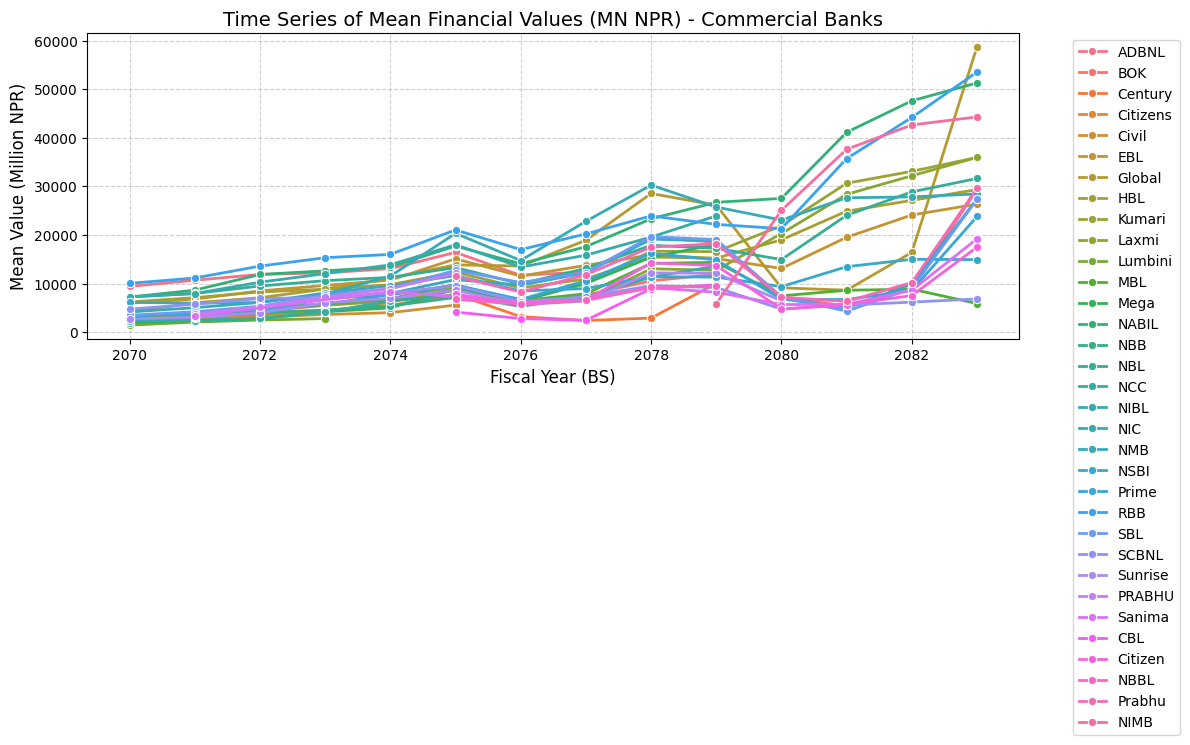

[INFO] Time series plot successfully saved to 'commercial_banks_timeseries.png'.


In [6]:
print("\n=== GENERATING TIME-SERIES AGGREGATION & PLOT ===")
# Aggregate mean value by year and commercial bank
ts_agg = (
    df.group_by(["year_bs", "bfi_name"])
    .agg(pl.col("value_mn_npr").mean().alias("mean_value"))
    .sort(["year_bs", "bfi_name"])
)

# Convert to pandas for plotting with Seaborn / Matplotlib
pdf = ts_agg.to_pandas()

plt.figure(figsize=(12, 6))
sns.lineplot(
    data=pdf,
    x="year_bs",
    y="mean_value",
    hue="bfi_name",
    marker="o",
    linewidth=2,
)
plt.title(
    "Time Series of Mean Financial Values (MN NPR) - Commercial Banks",
    fontsize=14,
)
plt.xlabel("Fiscal Year (BS)", fontsize=12)
plt.ylabel("Mean Value (Million NPR)", fontsize=12)
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()

output_plot = Path("commercial_banks_timeseries.png")
# plt.savefig(output_plot, dpi=300)
plt.show()
print(f"[INFO] Time series plot successfully saved to '{output_plot}'.")